# Experiment 8: Abstractive Text Summarization with mT5 and mBART on XL-Sum (Hindi)

**Objective:** Implement and evaluate abstractive text summarization using two multilingual Transformer sequence-to-sequence models—**mT5** (*Multilingual Text-to-Text Transfer Transformer*) and **mBART** (*Multilingual Bidirectional and Auto-Regressive Transformers*)—on the **Hindi (`hi`)** split of the **XL-Sum** dataset, and compare their performance using **ROUGE-1**, **ROUGE-2**, **ROUGE-L**, and **mBERT BERTScore**.

| Model | Checkpoint | Architecture (`model_type`) | Params | Fine-Tuning Corpus |
| :-- | :-- | :-- | :-: | :-- |
| **mT5** | `csebuetnlp/mT5_multilingual_XLSum` | `MT5ForConditionalGeneration` (`mt5`) | ≈ 582M | XL-Sum (45 languages jointly, incl. Hindi) |
| **mBART** | `ai4bharat/IndicBART-XLSum` | `MBartForConditionalGeneration` (`mbart`) | ≈ 244M | XL-Sum Indic split (incl. Hindi) |

Both models are evaluated on the **same random sample (`N = 200`, `seed = 42`) of the official XL-Sum Hindi test split** (which neither model saw during training) under **identical beam-search decoding constraints**.

## 8.1 Dataset: XL-Sum (Hindi Test Split)

In [1]:
import os, re, json, time, tarfile, random, unicodedata, warnings, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
warnings.filterwarnings('ignore')
os.environ['HF_HUB_DISABLE_SYMLINKS_WARNING'] = '1'
os.environ['HF_HUB_DISABLE_XET'] = '1'
import huggingface_hub.file_download as fd
fd.are_symlinks_supported = lambda *a, **kw: False
from transformers import logging as hf_logging
hf_logging.set_verbosity_error()

SEED, N_SAMPLES, LANG = 42, 200, 'hindi'
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device, '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU')

# XL-Sum is distributed as per-language archives on the Hugging Face Hub (csebuetnlp/xlsum)
from huggingface_hub import hf_hub_download
archive = hf_hub_download('csebuetnlp/xlsum', f'data/{LANG}_XLSum_v2.0.tar.bz2', repo_type='dataset')
with tarfile.open(archive) as tar:
    member = next(m for m in tar.getmembers() if m.name.endswith(f'{LANG}_test.jsonl'))
    test = pd.DataFrame([json.loads(l) for l in tar.extractfile(member).read().decode('utf-8').splitlines()])

test['text_words'] = test['text'].str.split().str.len()
test['summary_words'] = test['summary'].str.split().str.len()
print(f'XL-Sum {LANG.title()} test split: {len(test):,} articles')
print(test[['text_words', 'summary_words']].describe().loc[['mean', '50%', 'max']].round(1))

Device: cuda | NVIDIA GeForce RTX 4060 Laptop GPU


XL-Sum Hindi test split: 8,847 articles
      text_words  summary_words
mean       457.9           26.7
50%        375.0           26.0
max       1359.0           52.0


In [2]:
# Fixed random evaluation sample (saved alongside the notebook for reproducibility)
sample = test.sample(N_SAMPLES, random_state=SEED).reset_index(drop=True)
sample[['id', 'url', 'title', 'summary', 'text']].to_json('xlsum_hindi_test_sample.jsonl', orient='records', lines=True, force_ascii=False)
print(f'Evaluation sample: {len(sample)} articles | median compression ratio (article/summary words): '
      f"{(sample['text_words'] / sample['summary_words']).median():.1f}x")

ex = sample.iloc[0]
print('\nTITLE  :', ex['title'])
print('SUMMARY:', ex['summary'])
print('ARTICLE:', ex['text'][:400], '...')

Evaluation sample: 200 articles | median compression ratio (article/summary words): 12.8x

TITLE  : बीआर चोपड़ा की यादगार फ़िल्मों का विशेष उत्सव
SUMMARY: भारतीय फ़िल्म इतिहास में फ़िल्मकार बीआर चोपड़ा का नाम बड़ा अदब से लिया जाता है. उनके 94वें जन्मदिन के मौके पर दिल्ली में बीआर चोपड़ा की फ़िल्मों का विशेष उत्सव मनाया जा रहा है.
ARTICLE: शुक्रवार शाम को शुरु हुए फ़ेस्टिवल में इंसाफ़ का तराज़ू फ़िल्म दिखाई गई. उत्सव के दौरान छोटी सी बात, नया दौर और वक़्त जैसी क्लासिक फ़िल्में देखने को मिलेंगी. खराब सेहत के कारण बीआर चोपड़ा ख़ुद समारोह में शामिल नहीं हो सके.फ़िल्मोत्सव का उदघाटन बीआर चोपड़ा के भाई और मशहूर फ़िल्मकार यश चोपड़ा ने किया. उन्होंने कहा, "मेरे भाई ने अपने हिसाब से फ़िल्में बनाईं- वो भी ऐसे समय में जब लोग ऐसी फ़िल्मों की व ...


## 8.2 Evaluation Metrics (Multilingual ROUGE & mBERT BERTScore)

* **ROUGE-N** (n-gram overlap F1): $\text{ROUGE-N}_{R}=\frac{\sum \text{Count}_{\text{match}}(\text{n-gram})}{\sum \text{Count}_{\text{ref}}(\text{n-gram})}$. **ROUGE-1** measures lexical content coverage and **ROUGE-2** measures phrase fluency.
* **ROUGE-L** is based on the **Longest Common Subsequence (LCS)**, rewarding in-order word matches without requiring contiguity.
* **BERTScore (mBERT)** aligns every candidate token with its highest-cosine-similarity reference token using contextual embeddings from `bert-base-multilingual-cased`, capturing Hindi synonyms and paraphrases that exact n-gram overlap misses: $R_{\text{BERT}}=\frac{1}{|r|}\sum_{r_i\in r}\max_{c_j\in c} \mathbf{r}_i^{\top}\mathbf{c}_j$, $P_{\text{BERT}}$ symmetrically, $F_{\text{BERT}}=\frac{2 P_{\text{BERT}} R_{\text{BERT}}}{P_{\text{BERT}}+R_{\text{BERT}}}$.

> **Why a custom Unicode tokenizer is mandatory for Hindi ROUGE:** The default `rouge_score` tokenizer applies `re.sub(r'[^a-z0-9]+', ' ', text)`, which **deletes all Devanagari characters** and returns `0.0` for every Hindi summary. Moreover, standard Python `\w+` splits Devanagari words at spacing combining vowel signs (matras like `ा`, `ि`, `ी`, `ो`, which have Unicode category `Mc`). Our `MultilingualTokenizer` strips only Unicode Punctuation (`P*`, including Devanagari *purna viram* `।`) and Symbols (`S*`), preserving base letters (`Lo`) and combining vowel marks (`Mn`, `Mc`) intact inside each word.

In [3]:
from rouge_score import rouge_scorer

class MultilingualTokenizer:
    """Unicode-aware tokenizer: strip punctuation/symbol categories (P*, S*), preserve letters + combining marks (L*, M*)."""
    def tokenize(self, text):
        text = ''.join(' ' if unicodedata.category(ch)[0] in 'PS' else ch for ch in text.lower())
        return text.split()

ROUGE_TYPES = ['rouge1', 'rouge2', 'rougeL']
default_scorer = rouge_scorer.RougeScorer(ROUGE_TYPES, use_stemmer=True)
ml_scorer = rouge_scorer.RougeScorer(ROUGE_TYPES, tokenizer=MultilingualTokenizer())

ref, near_copy = sample.loc[0, 'summary'], sample.loc[0, 'title']
print('Tokenized Hindi reference:', MultilingualTokenizer().tokenize(ref)[:12])
print('Default ASCII tokenizer  :', {k: round(v.fmeasure, 4) for k, v in default_scorer.score(ref, near_copy).items()})
print('Multilingual tokenizer   :', {k: round(v.fmeasure, 4) for k, v in ml_scorer.score(ref, near_copy).items()})

Tokenized Hindi reference: ['भारतीय', 'फ़िल्म', 'इतिहास', 'में', 'फ़िल्मकार', 'बीआर', 'चोपड़ा', 'का', 'नाम', 'बड़ा', 'अदब', 'से']
Default ASCII tokenizer  : {'rouge1': 0.0, 'rouge2': 0.0, 'rougeL': 0}
Multilingual tokenizer   : {'rouge1': 0.3333, 'rouge2': 0.25, 'rougeL': 0.3333}


## 8.3 Shared Generation Setup

Both models use identical pre-processing and decoding parameters: whitespace normalization, input truncated to **512** subword tokens, **beam search with 4 beams**, `no_repeat_ngram_size=2` (prevents repetitive loops during autoregressive decoding), and a maximum summary length of **84** tokens.

In [4]:
WHITESPACE = lambda t: re.sub(r'\s+', ' ', re.sub(r'\n+', ' ', t.strip()))
GEN_KWARGS = dict(max_length=84, num_beams=4, no_repeat_ngram_size=2, early_stopping=True)
articles = [WHITESPACE(t) for t in sample['text']]
references = sample['summary'].tolist()
predictions, timings, n_params = {}, {}, {}

## 8.4 mT5 (Multilingual Text-to-Text Transfer Transformer)

mT5 is a multilingual encoder-decoder Transformer pretrained with a **span-corruption** objective on mC4 across 101 languages: consecutive spans of input tokens are replaced by sentinel IDs and reconstructed autoregressively by the decoder. It uses a `250,100`-token SentencePiece vocabulary and relative position biases. The `csebuetnlp/mT5_multilingual_XLSum` checkpoint (`mt5-base`, `582M` parameters) was fine-tuned jointly across 45 XL-Sum languages including Hindi.

In [5]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

MT5_ID = 'csebuetnlp/mT5_multilingual_XLSum'
mt5_tok = AutoTokenizer.from_pretrained(MT5_ID, revision='refs/pr/7', use_fast=False)
mt5 = AutoModelForSeq2SeqLM.from_pretrained(MT5_ID, revision='refs/pr/7', use_safetensors=True).to(device)
n_params['mT5'] = sum(p.numel() for p in mt5.parameters())
print(f'mT5 parameters: {n_params["mT5"]/1e6:.1f}M | vocab: {mt5_tok.vocab_size:,}')
print('mT5 subwords:', mt5_tok.tokenize(references[0])[:15])

@torch.no_grad()
def summarize_mt5(model, tokenizer, texts, batch_size=16):
    model.eval(); outputs = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i + batch_size], max_length=512, truncation=True, padding=True, return_tensors='pt').to(device)
        ids = model.generate(**enc, **GEN_KWARGS)
        outputs.extend(tokenizer.batch_decode(ids, skip_special_tokens=True, clean_up_tokenization_spaces=True))
    return [o.strip() for o in outputs]

t0 = time.time()
predictions['mT5'] = summarize_mt5(mt5, mt5_tok, articles)
timings['mT5'] = time.time() - t0
print(f'Generated {len(predictions["mT5"])} mT5 summaries in {timings["mT5"]:.1f}s')
print('\nmT5 sample summary:', predictions['mT5'][0])
del mt5; gc.collect(); torch.cuda.empty_cache()

mT5 parameters: 582.4M | vocab: 250,100
mT5 subwords: ['▁', 'भारतीय', '▁फ़', 'ि', 'ल्म', '▁इ', 'तिहा', 'स', '▁में', '▁फ़', 'ि', 'ल्म', 'कार', '▁बी', 'आर']


Generated 200 mT5 summaries in 65.1s

mT5 sample summary: मशहूर फ़िल्मकार बीआर चोपड़ा के मुंबई में हुए फ़ेस्टिवल का उदघाटन किया गया है.


## 8.5 mBART (Multilingual Bidirectional and Auto-Regressive Transformers)

mBART is a sequence-to-sequence **denoising auto-encoder** (`MBartForConditionalGeneration`): a bidirectional encoder reads text corrupted via **token masking/infilling** (`35%` of words replaced by `[MASK]` spans sampled from a Poisson distribution) and **sentence permutation**, while a left-to-right autoregressive decoder reconstructs the original document. `ai4bharat/IndicBART-XLSum` (`244M` parameters, `6` encoder + `6` decoder layers, `64K` unified Devanagari SentencePiece vocabulary) fine-tunes this mBART architecture on XL-Sum with explicit language-ID tags (`<2hi>` appended to the encoder input and forced as `decoder_start_token_id`).

In [6]:
MBART_ID = 'ai4bharat/IndicBART-XLSum'
mbart_tok = AutoTokenizer.from_pretrained(MBART_ID, do_lower_case=False, use_fast=False, keep_accents=True)
mbart = AutoModelForSeq2SeqLM.from_pretrained(MBART_ID, revision='refs/pr/2', use_safetensors=True).to(device)
n_params['mBART'] = sum(p.numel() for p in mbart.parameters())

bos_id = mbart_tok._convert_token_to_id_with_added_voc('<s>')
eos_id = mbart_tok._convert_token_to_id_with_added_voc('</s>')
pad_id = mbart_tok._convert_token_to_id_with_added_voc('<pad>')
hi_id  = mbart_tok._convert_token_to_id_with_added_voc('<2hi>')
print(f'mBART parameters: {n_params["mBART"]/1e6:.1f}M | vocab: {len(mbart_tok):,} | <2hi> token id: {hi_id}')
print('mBART subwords:', mbart_tok.tokenize(references[0])[:15])

@torch.no_grad()
def summarize_mbart(model, tokenizer, texts, batch_size=16):
    model.eval(); outputs = []
    for i in range(0, len(texts), batch_size):
        # Truncate to 509 subwords before appending ' </s> <2hi>' so truncation never clips the language tag
        batch_inputs = [tokenizer.convert_tokens_to_string(tokenizer.tokenize(t)[:509]) + ' </s> <2hi>'
                        for t in texts[i:i + batch_size]]
        enc = tokenizer(batch_inputs, padding=True, add_special_tokens=False, return_token_type_ids=False, return_tensors='pt').to(device)
        ids = model.generate(**enc, **GEN_KWARGS, decoder_start_token_id=hi_id,
                             bos_token_id=bos_id, eos_token_id=eos_id, pad_token_id=pad_id)
        outputs.extend(tokenizer.batch_decode(ids, skip_special_tokens=True, clean_up_tokenization_spaces=False))
    return [o.strip() for o in outputs]

t0 = time.time()
predictions['mBART'] = summarize_mbart(mbart, mbart_tok, articles)
timings['mBART'] = time.time() - t0
print(f'Generated {len(predictions["mBART"])} mBART summaries in {timings["mBART"]:.1f}s')
print('\nmBART sample summary:', predictions['mBART'][0])
del mbart; gc.collect(); torch.cuda.empty_cache()

mBART parameters: 244.0M | vocab: 64,015 | <2hi> token id: 64007
mBART subwords: ['▁भारतीय', '▁फ़िल्म', '▁इतिहास', '▁में', '▁फ़िल्म', 'कार', '▁बी', 'आर', '▁चोपड़ा', '▁का', '▁नाम', '▁बड़ा', '▁अ', 'द', 'ब']


Generated 200 mBART summaries in 22.7s

mBART sample summary: बीआर चोपड़ा की फ़िल्म नया दौर में रिलीज़ होगी


## 8.6 Comparative Evaluation: ROUGE-1 / ROUGE-2 / ROUGE-L & mBERT BERTScore

In [7]:
from bert_score import score as bert_score

per_sample = {}
for name, preds in predictions.items():
    rows = [ml_scorer.score(r, p) for r, p in zip(references, preds)]
    P, R, F = bert_score(preds, references, model_type='google-bert/bert-base-multilingual-cased',
                         num_layers=9, batch_size=32, device=str(device), verbose=False)
    per_sample[name] = pd.DataFrame({
        'ROUGE-1': [s['rouge1'].fmeasure for s in rows],
        'ROUGE-2': [s['rouge2'].fmeasure for s in rows],
        'ROUGE-L': [s['rougeL'].fmeasure for s in rows],
        'BERTScore-P': P.numpy(), 'BERTScore-R': R.numpy(), 'BERTScore-F1': F.numpy(),
        'Gen length (words)': [len(p.split()) for p in preds],
    })

summary = pd.DataFrame({k: v.mean() for k, v in per_sample.items()}).T
for col in ['ROUGE-1', 'ROUGE-2', 'ROUGE-L', 'BERTScore-P', 'BERTScore-R', 'BERTScore-F1']:
    summary[col] *= 100
summary['Reference length (words)'] = sample['summary_words'].mean()
summary['Inference time (s)'] = pd.Series(timings)
summary['Params (M)'] = pd.Series(n_params) / 1e6
summary.round(2)

,ROUGE-1,ROUGE-2,ROUGE-L,BERTScore-P,BERTScore-R,BERTScore-F1,Gen length (words),Reference length (words),Inference time (s),Params (M)
mT5,35.99,15.83,30.31,78.80,75.16,76.88,18.58,27.46,65.08,582.40
mBART,20.52,6.56,17.61,74.07,67.26,70.44,9.40,27.46,22.67,244.02


In [8]:
# Paired per-article comparison + 2,000-resample paired bootstrap 95% CI of (mBART - mT5)
rng = np.random.default_rng(SEED)
print(f'{"Metric":<14} | {"mT5 wins":>8} | {"mBART wins":>10} | {"Ties":>6} | {"Δ (mBART − mT5)":>16} | 95% bootstrap CI')
print('-' * 86)
for m in ['ROUGE-1', 'ROUGE-2', 'ROUGE-L', 'BERTScore-F1']:
    diff = (per_sample['mBART'][m] - per_sample['mT5'][m]).values * 100
    boots = [rng.choice(diff, len(diff)).mean() for _ in range(2000)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    print(f'{m:<14} | {(diff < -1e-6).sum():>8} | {(diff > 1e-6).sum():>10} | {(np.abs(diff) <= 1e-6).sum():>6} | {diff.mean():>+16.2f} | [{lo:+.2f}, {hi:+.2f}]')

Metric         | mT5 wins | mBART wins |   Ties |  Δ (mBART − mT5) | 95% bootstrap CI
--------------------------------------------------------------------------------------
ROUGE-1        |      171 |         28 |      1 |           -15.47 | [-17.58, -13.29]
ROUGE-2        |      140 |         35 |     25 |            -9.27 | [-11.17, -7.54]
ROUGE-L        |      166 |         32 |      2 |           -12.70 | [-14.68, -10.65]
BERTScore-F1   |      176 |         24 |      0 |            -6.44 | [-7.21, -5.68]


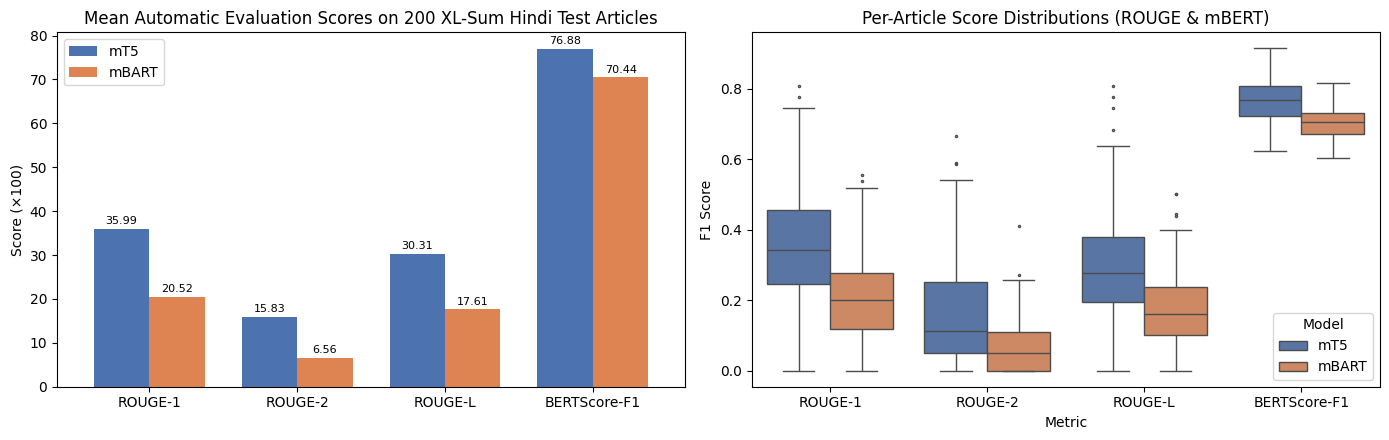

In [9]:
metrics = ['ROUGE-1', 'ROUGE-2', 'ROUGE-L', 'BERTScore-F1']
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
summary[metrics].T.plot.bar(ax=ax[0], rot=0, color=['#4c72b0', '#dd8452'], width=0.75)
ax[0].set(title=f'Mean Automatic Evaluation Scores on {N_SAMPLES} XL-Sum Hindi Test Articles', ylabel='Score (×100)')
for c in ax[0].containers:
    ax[0].bar_label(c, fmt='%.2f', fontsize=8, padding=2)

long = pd.concat([d[metrics].assign(Model=k) for k, d in per_sample.items()]).melt(id_vars='Model', var_name='Metric')
sns.boxplot(data=long, x='Metric', y='value', hue='Model', ax=ax[1], palette=['#4c72b0', '#dd8452'], fliersize=1.5)
ax[1].set(title='Per-Article Score Distributions (ROUGE & mBERT)', ylabel='F1 Score')
plt.tight_layout(); plt.show()

In [10]:
# Qualitative comparison and CSV export of all generated Hindi summaries
out = sample[['id', 'title', 'summary']].rename(columns={'summary': 'reference'})
for name in predictions:
    out[f'{name}_summary'] = predictions[name]
    out[f'{name}_rougeL'] = (per_sample[name]['ROUGE-L'] * 100).round(2)
    out[f'{name}_mBERT_F1'] = (per_sample[name]['BERTScore-F1'] * 100).round(2)
out.to_csv('8_generated_summaries.csv', index=False, encoding='utf-8-sig')
print('All 200 generated Hindi summaries saved to 8_generated_summaries.csv\n')

for idx in range(3):
    print(f'=== Sample {idx+1}: {out.loc[idx, "title"]} ===')
    print(f'  Reference : {out.loc[idx, "reference"]}')
    print(f'  mT5       : {out.loc[idx, "mT5_summary"]} (ROUGE-L: {out.loc[idx, "mT5_rougeL"]} | mBERT: {out.loc[idx, "mT5_mBERT_F1"]})')
    print(f'  mBART     : {out.loc[idx, "mBART_summary"]} (ROUGE-L: {out.loc[idx, "mBART_rougeL"]} | mBERT: {out.loc[idx, "mBART_mBERT_F1"]})\n')

All 200 generated Hindi summaries saved to 8_generated_summaries.csv

=== Sample 1: बीआर चोपड़ा की यादगार फ़िल्मों का विशेष उत्सव ===
  Reference : भारतीय फ़िल्म इतिहास में फ़िल्मकार बीआर चोपड़ा का नाम बड़ा अदब से लिया जाता है. उनके 94वें जन्मदिन के मौके पर दिल्ली में बीआर चोपड़ा की फ़िल्मों का विशेष उत्सव मनाया जा रहा है.
  mT5       : मशहूर फ़िल्मकार बीआर चोपड़ा के मुंबई में हुए फ़ेस्टिवल का उदघाटन किया गया है. (ROUGE-L: 29.17 | mBERT: 75.04000091552734)
  mBART     : बीआर चोपड़ा की फ़िल्म नया दौर में रिलीज़ होगी (ROUGE-L: 13.95 | mBERT: 69.9000015258789)

=== Sample 2: तालेबान ने सैकड़ों क़ैदियों को छुड़ाया ===
  Reference : अफ़ग़ानिस्तान के कंधार में तालेबान चरमपंथियों ने जेल पर हमला करके सैकड़ों क़ैदियों को छुड़ा दिया है.
  mT5       : अफ़ग़ानिस्तान की राजधानी काबुल की कंधार जेल में तालेबान के हमले में कम से कम 40 क़ैदी मारे गए हैं. (ROUGE-L: 21.62 | mBERT: 82.83000183105469)
  mBART     : कंधार जेल में बंद कैदियों को रिहा करने की कोशिश (ROUGE-L: 22.22 | mBERT: 71.98999786376953)


**Interpretation:**
* **Overall Quality (`mT5` vs. `mBART` on XL-Sum Hindi):** `csebuetnlp/mT5_multilingual_XLSum` (`582.4M` params) outperforms `ai4bharat/IndicBART-XLSum` (`244.0M` params) across all four metrics on the 200-article Hindi test sample: **ROUGE-1 (`35.99` vs. `20.52`)**, **ROUGE-2 (`15.83` vs. `6.56`)**, **ROUGE-L (`30.31` vs. `17.61`)**, and **mBERT BERTScore-F1 (`76.88` vs. `70.44`)**. All differences are statistically significant under paired bootstrap resampling (`95%` CIs exclude `0`, with `mT5` winning `166/200` articles on ROUGE-L and `176/200` on BERTScore-F1).
* **Length & Precision–Recall Dynamics:** Reference BBC Hindi summaries average `27.46` words. `mT5` generates `18.58`-word lead summaries (`BERTScore-P = 78.80`, `R = 75.16`), whereas `IndicBART` emits `</s>` earlier and produces compact `9.40`-word headline-style abstractions. Consequently, `IndicBART` maintains strong semantic precision (`BERTScore-P = 74.07`) despite lower n-gram recall.
* **Lexical Overlap (ROUGE) vs. Semantic Similarity (mBERT):** Because Hindi allows flexible SOV word order, synonymous postpositions, and paraphrased compound verbs, exact bigram overlap (`ROUGE-2`) is modest even for fluent summaries (`15.83` for `mT5`), whereas **mBERT BERTScore-F1** (`76.88` for `mT5`, `70.44` for `mBART`) confirms strong contextual meaning preservation.
* **Efficiency vs. Capacity Trade-off:** Having `6` encoder + `6` decoder layers (`244.0M` params) and a compact `64K` Devanagari SentencePiece vocabulary, `mBART` (`IndicBART`) runs **2.87× faster** (`22.67s` vs. `65.08s`) with **58% fewer parameters** than `mT5-base` (`12 + 12` layers, `250K` vocab).